## 6BUIS017W CWK - Market Analysis and Stock Segmentation Using RFM

## Setup

In [27]:
import datetime as dt
import pandas as pd
import numpy as np
import yfinance as yf
import matplotlib.pyplot as plt
import sklearn, scipy

print("pandas", pd.__version__, "| numpy", np.__version__, "| yfinance", yf.__version__)
print("scikit-learn", sklearn.__version__, "| scipy", scipy.__version__)

pandas 2.2.3 | numpy 2.4.6 | yfinance 0.2.66
scikit-learn 1.6.1 | scipy 1.16.3


# Task 1 – Data preparation and feature engineering

## 1.1 Ticker selection and data acquisition

In [28]:
# Extracting S&P 500 tickers from Wikipedia using Pandas
url = 'https://en.wikipedia.org/wiki/List_of_S%26P_500_companies'               # Wikipedia page with the S&P 500 table
table = pd.read_html(url, storage_options={"User-Agent": "Mozilla/5.0"})         # read every table on the page (User-Agent avoids a 403 block)
sp500_df = table[0]                                                              # the first table is the constituent list

tickers = sp500_df['Symbol'].tolist()                                            # the Symbol column as a Python list
tickers = [t.replace('.', '-') for t in tickers]                                 # Yahoo uses "-" not "." (BRK.B becomes BRK-B)

print('Total tickers extracted:', len(tickers))

retrieval_date = dt.date.today().isoformat()                                     # today's date as text, e.g. 2026-11-21
sp500_df["Ticker"] = tickers                                                     # add the cleaned tickers as a column so they stay with the sector
sp500_df["Retrieved"] = retrieval_date                                           # add the retrieval date as a column
sp500_df[['Symbol', 'Ticker', 'Security', 'GICS Sector', 'Retrieved']].to_csv("sp500_tickers.csv", index=False)   # Export the selected columns to a CSV file
print('Retrieved on', retrieval_date)

Total tickers extracted: 503
Retrieved on 2026-11-23


In [29]:
# Loading Daily Market Data through yfinance
start = '2021-01-01'                                                             # first day to download
end = '2025-01-01'                                                               # day after the last day wanted

df_all = yf.download(tickers, start=start, end=end, auto_adjust=False)           # auto_adjust=False keeps both Close and Adj Close
df = df_all['Adj Close']                                                         # Extract adjusted closing prices
close = df_all['Close']                                                          # Extract close prices (used for Monetary)
volume = df_all['Volume']                                                        # Extract trading volume (used for high-volume events)

market_prices = yf.download("^GSPC", start=start, end=end, auto_adjust=False)["Adj Close"]   # S&P 500 index prices (the benchmark)

print('Shape:', df.shape, '|', df.index.min().date(), 'to', df.index.max().date())

# Save the downloaded datasets as CSV files to preserve the original data
df.to_csv("adj_close_2021_2024.csv")
close.to_csv("close_2021_2024.csv")
volume.to_csv("volume_2021_2024.csv")
market_prices.to_csv("sp500_index_2021_2024.csv")

[*********************100%***********************]  503 of 503 completed
ERROR:yfinance:
5 Failed downloads:
ERROR:yfinance:['VYLR', 'HONA', 'SNDK', 'FDXF', 'Q']: YFPricesMissingError('possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01) (Yahoo error = "Data doesn\'t exist for startDate = 1609477200, endDate = 1735707600")')
[*********************100%***********************]  1 of 1 completed


Shape: (1005, 503) | 2021-01-04 to 2024-12-31


## 1.2 Data validation and alignment

In [30]:
# Check whether the dataset contains duplicate dates or dates in the wrong order.
print("Duplicate dates:", df.index.duplicated().sum())                           # Counts repeated dates; expected result is 0
print("Dates in order:", df.index.is_monotonic_increasing)                       # Check whether dates are sorted from oldest to newest.

no_data = df.isna().all()                                                        # Flags shares a share whose every price is missing (nothing downloaded)
incomplete = df.isna().any() & ~no_data                                          # Flags shares with SOME missing prices
bad_price = (df <= 0).any() | (close <= 0).any()                                 # Flags shares with zero or negative adjusted or raw closing prices.
bad_volume = (volume < 0).any() | ((volume == 0).mean() > 0.05)                 # # Flags negative volume or shares with zero volume on more than 5% of trading days.

# Combine all validation results into one exclusion log, with one row per ticker.
exclusion_log = pd.DataFrame({"No data": no_data, "Incomplete history": incomplete,
                              "Non-positive price": bad_price, "Volume error": bad_volume})
excluded = exclusion_log[exclusion_log.any(axis=1)]                              # Identify shares that violate at least one data quality rule.
excluded.to_csv("exclusion_log.csv")                                             # save the list of excluded shares

valid = exclusion_log.index[~exclusion_log.any(axis=1)].tolist()
print(exclusion_log.sum())                                                       # Summarise the number of excluded and valid shares, and the number of violations per rule.

Duplicate dates: 0
Dates in order: True
No data                5
Incomplete history    10
Non-positive price     0
Volume error           1
dtype: int64


In [31]:
# Check for unusually large one-day price changes that may indicate unadjusted stock splits.
daily_change = close[valid].pct_change(fill_method=None)                         # Calculates the daily percentage change in closing prices for valid shares.
flag = (daily_change < -0.4) | (daily_change > 0.6)                              # Identifies price drops greater than 40% or increases greater than 60%.
for t in flag.columns[flag.any()]:                                               # Goes through only shares with at least one flagged price change.
    print(t, daily_change[t][flag[t]].round(3).to_dict())                        # Prints each identified share's ticker, date and percentage price change.

CVNA {Timestamp('2022-12-07 00:00:00'): -0.429}
DXCM {Timestamp('2024-07-26 00:00:00'): -0.407}
GL {Timestamp('2024-04-11 00:00:00'): -0.531}


## 1.3 Weekly return and weekly beta

### 1.3.1 Mean weekly return

In [32]:
# Keep only valid shares and transpose the DataFrame so rows represent shares and columns represent dates.
df1 = df[valid].T

def calculate_weekly_returns(df1, shares=None):
    prices = df1 if shares is None else df1.loc[shares]                          # use all shares unless a list is given
    prices = prices.T.copy()                                                     # Put dates in rows and shares in columns.
    prices.index = pd.to_datetime(prices.index)                                  # Convert the index into dates.
    prices = prices.sort_index()                                                 # Sort dates from oldest to newest.
    weekly_prices = prices.resample("W-FRI").last()                              # Get the last price of each week.
    return weekly_prices.pct_change(fill_method=None)                            # Calculate the weekly price change.

# Calculate weekly returns for all valid shares.
weekly_returns = calculate_weekly_returns(df1)

# Remove the incomplete final week.
last_complete_week = "2024-12-27"
weekly_returns = weekly_returns.loc[weekly_returns.index <= last_complete_week]  # keep only weeks up to 27 Dec 2024

# Calculate weekly returns for the S&P 500.
market_weekly_returns = market_prices.resample("W-FRI").last().pct_change(fill_method=None)
market_weekly_returns = market_weekly_returns.loc[market_weekly_returns.index <= last_complete_week]
market_weekly_returns.columns = ["^GSPC"]                                        # Name the S&P 500 column.

# Check whether shares and the S&P 500 have the same weekly dates.
print("Same weeks for shares and benchmark:", weekly_returns.index.equals(market_weekly_returns.index))
print("Weeks:", weekly_returns.index[0].date(), "to", weekly_returns.index[-1].date())

# Calculate the average weekly return for each share.
mean_return = weekly_returns.mean()

# Count missing values after the first week.
print("Missing values after the first week:", int(weekly_returns.iloc[1:].isna().sum().sum()))

# Display summary statistics of the average weekly returns.
mean_return.describe().round(4)

Same weeks for shares and benchmark: True
Weeks: 2021-01-08 to 2024-12-27
Missing values after the first week: 0


,0
count,487.0000
mean,0.0029
std,0.0026
min,-0.0045
25%,0.0012
50%,0.0026
75%,0.0042
max,0.0178


### 1.3.2 Weekly beta

In [33]:
# Calculate the beta value for each share.
def calculate_weekly_beta(weekly_returns, market_returns, min_weeks=52):
    if min_weeks < 2:                                                            # Make sure at least two weeks are required.
        raise ValueError("min_weeks must be at least 2.")

    results = []                                                                 # Store the results for each share.

    for share in weekly_returns.columns:                                         # go through the shares one by one
        paired = pd.concat(
            [weekly_returns[share].rename("share"),                              # get the share's weekly returns
             market_returns.rename("market")],                                   # get the benchmark's weekly returns
            axis=1                                                               # Match both returns by date.
        ).replace([np.inf, -np.inf], np.nan).dropna()                            # Remove invalid and missing values.

        variance = paired["market"].var(ddof=1)                                  # Calculate the market's variance.
        beta = np.nan                                                            # Set beta as missing until the checks are passed.

        if len(paired) >= min_weeks and variance > 0:                            # Check for at least 52 weeks and non-zero variance.
            beta = paired["share"].cov(paired["market"]) / variance              # Calculate beta using covariance and variance.
        results.append({"Share": share, "Beta": beta, "Paired_weeks": len(paired)})

    return pd.DataFrame(results, columns=["Share", "Beta", "Paired_weeks"]).set_index("Share")

# Calculate beta for all valid shares.
beta_df = calculate_weekly_beta(weekly_returns, market_weekly_returns["^GSPC"])  # run it for all shares

# Display the number of weekly observations used for each share.
print("Weekly observations per share:", beta_df["Paired_weeks"].unique())

# Count shares that could not be assigned a beta value.
print("Shares with missing beta:", int(beta_df["Beta"].isna().sum()))

# Display summary statistics of the beta values.
beta_df["Beta"].describe().round(4)

Weekly observations per share: [207]
Shares with missing beta: 0


,Beta
count,487.0000
mean,0.9736
std,0.4069
min,0.0555
25%,0.6666
50%,0.9480
75%,1.1794
max,3.7786


In [34]:
# BRIEF: recompute beta a different way for three shares.
# Uses pandas cov() and var() from the lecture notes to verify the original calculation.
for t in ["AAPL", "MSFT", "JPM"]:
    if t not in valid:                                                           # skip a ticker that was excluded
        continue
    pair = pd.concat([weekly_returns[t], market_weekly_returns["^GSPC"]], axis=1).dropna()  # matched weekly returns
    variance = pair.iloc[:, 1].var(ddof=1)                                       # variance of market weekly returns
    covariance = pair.iloc[:, 0].cov(pair.iloc[:, 1])                            # covariance of share and market returns
    if variance > 0:
        check = covariance / variance                                            # independently calculated beta
        print(t, "check:", round(check, 4), "| function:", round(beta_df.loc[t, "Beta"], 4))

AAPL check: 1.1748 | function: 1.1748
MSFT check: 1.1286 | function: 1.1286
JPM check: 0.948 | function: 0.948


## 1.4 Adapted RFM calculations

In [35]:
# Calculate RFM values for each valid share.
results = []                                                                     # one result per share will be added here
for ticker in valid:                                                             # Go through each valid share.
    data = pd.DataFrame({"Close": close[ticker], "Volume": volume[ticker]}).sort_index()   # this share's Close and Volume by date

    average_volume = data["Volume"].shift(1).rolling(20).mean()                  # Calculate the average volume of the previous 20 days.
    data["HighVolume"] = data["Volume"] > 2 * average_volume                     # Identify days with more than twice the average volume.

    valid_days = data.loc[average_volume.notna()].copy()                         # Keep days with a complete 20-day average.

    if len(valid_days) < 60:                                                     # Check whether at least 60 trading days are available.
        print(f"{ticker}: insufficient history")
        continue

    recent = valid_days.tail(60)                                                 # get the last 60 trading sessions
    high_volume_days = valid_days.loc[valid_days["HighVolume"]]                  # get all days with high tading volume

    recency = (                                                                  # calendar days from the last date to the latest event
        (valid_days.index[-1].date() - high_volume_days.index[-1].date()).days
        if not high_volume_days.empty                                            # only if the share had any event
        else None
    )

    results.append({
        "Share": ticker,
        "AsOf": valid_days.index[-1].date(),                                     # Record the latest trading date.
        "Recency": recency,
        "Frequency": int(recent["HighVolume"].sum()),                            # Count high-volume days in the latest 60 trading days.
        "Monetary": round((recent["Close"] * recent["Volume"]).sum(), 2)         # Calculate total traded value over the latest 60 trading days.
    })

# Create a DataFrame containing the RFM values for each share.
rfm = pd.DataFrame(results, columns=["Share", "AsOf", "Recency", "Frequency", "Monetary"]).set_index("Share")
rfm["Recency"] = rfm["Recency"].astype("Int64")                                  # Allow whole numbers and missing values.

# Display the observation dates and shares without high-volume events.
print("Observation date(s):", rfm["AsOf"].unique())
print("Shares with no event (Recency missing):", int(rfm["Recency"].isna().sum()))

# Display summary statistics for the RFM values.
rfm.describe().round(2)

Observation date(s): [datetime.date(2024, 12, 31)]
Shares with no event (Recency missing): 0


,Recency,Frequency,Monetary
count,487.0,487.00,4.870000e+02
mean,20.41,2.99,3.936075e+10
std,21.32,1.33,1.290095e+11
min,4.0,0.00,1.297483e+09
25%,11.0,2.00,1.021356e+10
50%,11.0,3.00,1.670905e+10
75%,15.0,4.00,3.218869e+10
max,222.0,8.00,1.847697e+12


## 1.5 Metric interpretation and supporting evidence

In [36]:
# Worked example: Verifying RFM Calculations for One Share
t = "AAPL" if "AAPL" in valid else valid[0]                                      # AAPL, or the first valid share if AAPL is missing
data = pd.DataFrame({"Close": close[t], "Volume": volume[t]}).sort_index()
average_volume = data["Volume"].shift(1).rolling(20).mean()                      # mean of the previous 20 days
data["Threshold"] = 2 * average_volume                                           # the volume level that counts as an event
data["HighVolume"] = data["Volume"] > data["Threshold"]
valid_days = data.loc[average_volume.notna()]                                    # days with a full baseline
events = valid_days.loc[valid_days["HighVolume"]]                                # event days only
latest = events.index[-1]                                                        # date of the latest event
print(t, "observation date:", valid_days.index[-1].date())
print("Latest event:", latest.date(), "| volume:", int(events.loc[latest, "Volume"]),
      "| threshold:", round(events.loc[latest, "Threshold"]))
print("Recency =", (valid_days.index[-1] - latest).days, "days | table value:", rfm.loc[t, "Recency"])
recent = valid_days.tail(60)
print("60-session window:", recent.index[0].date(), "to", recent.index[-1].date())
print("Event days in window:", [d.date() for d in recent.index[recent["HighVolume"]]],
      "| Frequency =", int(recent["HighVolume"].sum()), "| table value:", rfm.loc[t, "Frequency"])
print("Monetary =", round((recent["Close"] * recent["Volume"]).sum()), "| table value:", round(rfm.loc[t, "Monetary"]))
print("Most common Recency values:\n", rfm["Recency"].value_counts().head(3))   # many shares share the same Recency (ties)

AAPL observation date: 2024-12-31
Latest event: 2024-12-20 | volume: 147495300 | threshold: 90009210
Recency = 11 days | table value: 11
60-session window: 2024-10-07 to 2024-12-31
Event days in window: [datetime.date(2024, 11, 25), datetime.date(2024, 12, 20)] | Frequency = 2 | table value: 2
Monetary = 623303377707 | table value: 623303377707
Most common Recency values:
 Recency
11    353
36     17
55     11
Name: count, dtype: Int64


In [37]:
# Independent Verification of Recency and Frequency Calculations
import random                                                                    # Import Python's random module.
random.seed(1)                                                                   # fixed seed so the same 25 are picked every run
mismatches = 0
for t in random.sample(valid, 25):                                               # 25 random valid shares
    vol = volume[t].tolist()                                                     # volumes as a plain list
    dates = volume.index                                                         # matching dates
    events = []
    for i in range(20, len(vol)):                                                # start at day 21 so 20 earlier days exist
        if vol[i] > 2 * (sum(vol[i - 20:i]) / 20):                               # volume > 2 x mean of the 20 days before
            events.append(i)                                                     # remember the day number
    last = len(vol) - 1                                                          # number of the last day
    R = (dates[last] - dates[events[-1]]).days                                   # calendar days since the latest event
    F = sum(1 for i in events if i >= last - 59)                                 # events inside the last 60 sessions
    if R != rfm.loc[t, "Recency"] or F != rfm.loc[t, "Frequency"]:
        mismatches += 1
print("Mismatches in R and F on 25 shares:", mismatches)

Mismatches in R and F on 25 shares: 0


In [38]:
# Create the Final Feature Table for Clustering

# Create a table with weekly return, beta and number of weeks.
final = pd.DataFrame({"Mean_Weekly_Return": mean_return, "Beta": beta_df["Beta"], "N_Weeks": beta_df["Paired_weeks"]})

# Add the RFM features (Recency, Frequency and Monetary).
final = final.join(rfm[["Recency", "Frequency", "Monetary"]].rename(columns={"Recency": "R", "Frequency": "F", "Monetary": "M"}))   # add R, F, M

# Add each share's GICS sector.
final["GICS Sector"] = sp500_df.set_index("Ticker")["GICS Sector"]
final.index.name = "Ticker"

# Remove shares with missing feature values.
final = final.dropna(subset=["Mean_Weekly_Return", "Beta", "R", "F", "M"]).copy()

# Convert Recency to a numerical format.
final["R"] = final["R"].astype(float)                                            # plain decimal numbers for the clustering code

# Apply log transformation to Monetary to reduce skewness.
final["log1p_M"] = np.log1p(final["M"])

# Save the final feature table as a CSV file.
final.to_csv("feature_table.csv")

# Display the number of shares and the first five rows.
print("Shares in the feature table:", len(final))
final.head()

Shares in the feature table: 487


,Mean_Weekly_Return,Beta,N_Weeks,R,F,M,GICS Sector,log1p_M
Ticker,,,,,,,,
A,0.001121,1.074724,207,11.0,2,1.400180e+10,Health Care,23.362451
AAPL,0.003930,1.174836,207,11.0,2,6.233034e+11,Information Technology,27.158299
ABBV,0.003749,0.425365,207,11.0,3,6.837054e+10,Health Care,24.948208
ABNB,0.001475,1.472709,207,11.0,3,3.652850e+10,Consumer Discretionary,24.321359
ABT,0.000971,0.583543,207,11.0,1,3.523027e+10,Health Care,24.285172


# Task 2 – Stock segmentation and sensitivity analysis

## 2.1 Feature preparation

In [39]:
# Check Feature Skewness and Outliers
cols = ["Mean_Weekly_Return", "Beta", "R", "F", "M", "log1p_M"]
print("Skewness:\n", final[cols].skew().round(2))                                # skewness: how lopsided each feature is
for c in ["Mean_Weekly_Return", "Beta", "R", "F", "log1p_M"]:
    q1, q3 = final[c].quantile([.25, .75])                                       # 25th and 75th percentiles
    iqr = q3 - q1                                                                # inter-quartile range
    n_out = ((final[c] < q1 - 1.5 * iqr) | (final[c] > q3 + 1.5 * iqr)).sum()    # values beyond 1.5 x IQR from the quartiles
    print(c, "outliers:", int(n_out))

# Standardise Features for Clustering

from sklearn.preprocessing import StandardScaler

X_rr = final[["Mean_Weekly_Return", "Beta"]]                                     # Select the risk and return features.
X_rfm = final[["R", "F", "log1p_M"]]                                             # Select the RFM features.

# Scale both feature sets separately.
Xs_rr = pd.DataFrame(StandardScaler().fit_transform(X_rr), index=final.index, columns=X_rr.columns)    # rescale to mean 0, spread 1
Xs_rfm = pd.DataFrame(StandardScaler().fit_transform(X_rfm), index=final.index, columns=X_rfm.columns)

# Store both scaled feature sets for later use.
matrices = {"RiskReturn": Xs_rr, "RFM": Xs_rfm}

Skewness:
 Mean_Weekly_Return     0.87
Beta                   1.11
R                      3.65
F                      0.43
M                     11.70
log1p_M                1.08
dtype: float64
Mean_Weekly_Return outliers: 15
Beta outliers: 10
R outliers: 113
F outliers: 2
log1p_M outliers: 13


## 2.2 Agglomerative clustering (Ward)

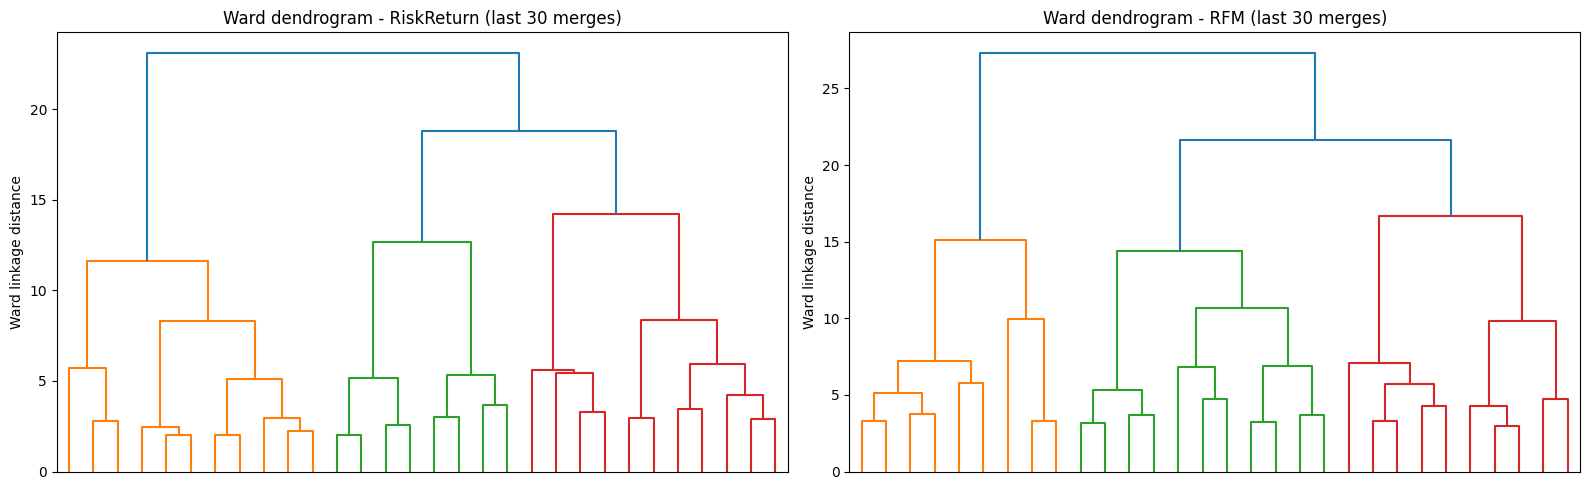


Ward - RFM
 k  Silhouette                           Sizes
 2       0.369                       [401, 86]
 3       0.261                  [222, 179, 86]
 4       0.251              [179, 136, 86, 86]
 5       0.270          [179, 136, 86, 76, 10]
 6       0.291      [161, 136, 86, 76, 18, 10]
 7       0.281   [136, 90, 86, 76, 71, 18, 10]
 8       0.282 [136, 90, 86, 76, 71, 18, 9, 1]

Ward - RiskReturn
 k  Silhouette                            Sizes
 2       0.340                        [395, 92]
 3       0.273                   [231, 164, 92]
 4       0.282               [183, 164, 92, 48]
 5       0.304            [183, 98, 92, 66, 48]
 6       0.320         [183, 98, 87, 66, 48, 5]
 7       0.324     [161, 98, 87, 66, 48, 22, 5]
 8       0.321 [161, 98, 66, 56, 48, 31, 22, 5]


In [40]:
# Perform Hierarchical Clustering and Evaluate Cluster Results

# Import clustering and evaluation tools.
from scipy.cluster.hierarchy import linkage, dendrogram, cut_tree
from sklearn.metrics import silhouette_score
# Apply Ward linkage to both feature sets.
links = {name: linkage(X, method="ward") for name, X in matrices.items()}

# Draw dendrograms for both feature sets.
fig, axes = plt.subplots(1, 2, figsize=(16, 5))                                  # Create two charts side by side.
for ax, (name, Z) in zip(axes, links.items()):
    dendrogram(Z, truncate_mode="lastp", p=30, no_labels=True, ax=ax)            # Show the last 30 merges.
    ax.set_title(f"Ward dendrogram - {name} (last 30 merges)")
    ax.set_ylabel("Ward linkage distance")
plt.tight_layout(); plt.savefig("dendrograms.png", dpi=150); plt.show()          # Save the dendrogram charts

# Test cluster numbers from 2 to 8 and record the results.
ward_rows = []
for name, X in matrices.items():
    for k in range(2, 9):
        labels = cut_tree(links[name], n_clusters=k).ravel() + 1                 # Divide shares into k clusters.
        sizes = sorted(np.bincount(labels)[1:].tolist(), reverse=True)           # Count shares in each cluster, largest first.
        ward_rows.append([name, "Ward", k, round(silhouette_score(X, labels), 3), None, sizes])
ward_diag = pd.DataFrame(ward_rows, columns=["Matrix", "Method", "k", "Silhouette", "Inertia", "Sizes"])

# Display the silhouette scores and cluster sizes for each feature set.
for name, g in ward_diag.groupby("Matrix"):
    print("\nWard -", name); print(g[["k", "Silhouette", "Sizes"]].to_string(index=False))

## 2.3 K-means clustering

In [41]:
# Perform K-Means Clustering and Compare Results

# Import the K-Means clustering method.
from sklearn.cluster import KMeans

km_rows = []
for name, X in matrices.items():
    for k in range(2, 9):
        kmeans = KMeans(n_clusters=k, n_init=50, random_state=42)                # 50 random starts, fixed seed for repeatable results
        kmeans.fit(X)                                                            # run the clustering
        sizes = sorted(np.bincount(kmeans.labels_).tolist(), reverse=True)       # cluster sizes, largest first
        km_rows.append([name, "KMeans", k, round(silhouette_score(X, kmeans.labels_), 3), round(kmeans.inertia_, 1), sizes])
km_diag = pd.DataFrame(km_rows, columns=["Matrix", "Method", "k", "Silhouette", "Inertia", "Sizes"])
for name, g in km_diag.groupby("Matrix"):
    print("\nK-means -", name); print(g[["k", "Silhouette", "Inertia", "Sizes"]].to_string(index=False))

pd.concat([ward_diag, km_diag]).to_csv("cluster_diagnostics.csv", index=False)   # save both tables


K-means - RFM
 k  Silhouette  Inertia                             Sizes
 2       0.423   1069.5                         [419, 68]
 3       0.325    799.3                    [273, 151, 63]
 4       0.341    611.2                [213, 122, 91, 61]
 5       0.358    516.0            [199, 122, 87, 68, 11]
 6       0.346    438.9       [144, 120, 105, 67, 40, 11]
 7       0.340    388.3    [137, 120, 104, 68, 46, 11, 1]
 8       0.342    343.0 [152, 101, 89, 66, 48, 19, 11, 1]

K-means - RiskReturn
 k  Silhouette  Inertia                            Sizes
 2       0.387    623.2                       [344, 143]
 3       0.328    462.7                  [203, 165, 119]
 4       0.326    372.7              [160, 154, 132, 41]
 5       0.340    310.9          [166, 129, 106, 49, 37]
 6       0.327    266.3       [135, 115, 85, 76, 56, 20]
 7       0.329    227.9    [127, 105, 84, 78, 47, 41, 5]
 8       0.357    195.2 [140, 79, 77, 76, 45, 36, 29, 5]


/tmp/ipykernel_2326/2216972609.py:17: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  pd.concat([ward_diag, km_diag]).to_csv("cluster_diagnostics.csv", index=False)   # save both tables


## 2.4 Cluster profiles and algorithm comparison

In [42]:
# Assign Shares to the Final Clusters

# Set the number of clusters for each feature set and method.
K = {("RiskReturn", "KMeans"): 5, ("RiskReturn", "Ward"): 5,
     ("RFM", "KMeans"): 4,        ("RFM", "Ward"): 3}

assign = pd.DataFrame(index=final.index)                                         # one column of cluster numbers per solution
for (name, method), k in K.items():
    X = matrices[name]
    if method == "Ward":
        assign[f"{name}_{method}"] = cut_tree(links[name], n_clusters=k).ravel() + 1   # Assign Ward cluster numbers starting from 1.
    else:
        assign[f"{name}_{method}"] = KMeans(n_clusters=k, n_init=50, random_state=42).fit(X).labels_   # Assign K-Means cluster numbers starting from 0.
final.join(assign).to_csv("cluster_assignments.csv")

# Display the number of shares in each cluster.
for col in assign.columns:
    print(col, assign[col].value_counts().sort_index().to_dict())

RiskReturn_KMeans {0: 106, 1: 37, 2: 166, 3: 49, 4: 129}
RiskReturn_Ward {1: 183, 2: 92, 3: 98, 4: 48, 5: 66}
RFM_KMeans {0: 213, 1: 122, 2: 61, 3: 91}
RFM_Ward {1: 222, 2: 179, 3: 86}


In [43]:
# Compare the Features of Each Cluster

# Select the features to compare.
tmp = final[["Mean_Weekly_Return", "Beta", "R", "F"]].copy()
tmp["M_bn_USD"] = final["M"] / 1e9                                               # Convert traded value into billions of US dollars.
pd.set_option("display.width", 200)                                              # show wide tables on one line
for col in assign.columns:
    g = tmp.groupby(assign[col])                                                 # group the shares by cluster
    profile = g.mean().round(3)                                                  # average of every feature per cluster
    profile["median_M_bn"] = g["M_bn_USD"].median().round(2)                     # median traded value (the mean is pulled up by giants)
    profile["n"] = g.size()                                                      # shares per cluster
    print("\n", col); print(profile)


 RiskReturn_KMeans
                   Mean_Weekly_Return   Beta       R      F  M_bn_USD  median_M_bn    n
RiskReturn_KMeans                                                                      
0                               0.000  1.036  19.085  3.028    18.765        13.37  106
1                               0.009  1.450  26.946  3.324    95.309        24.65   37
2                               0.004  0.976  16.771  2.825    38.029        18.33  166
3                               0.002  1.630  24.714  3.143    90.427        31.80   49
4                               0.002  0.534  22.667  3.008    22.554        15.04  129

 RiskReturn_Ward
                 Mean_Weekly_Return   Beta       R      F  M_bn_USD  median_M_bn    n
RiskReturn_Ward                                                                      
1                             0.001  0.973  17.732  3.005    19.779        13.01  183
2                             0.006  1.298  23.674  3.196    78.781        24.18   92
3 

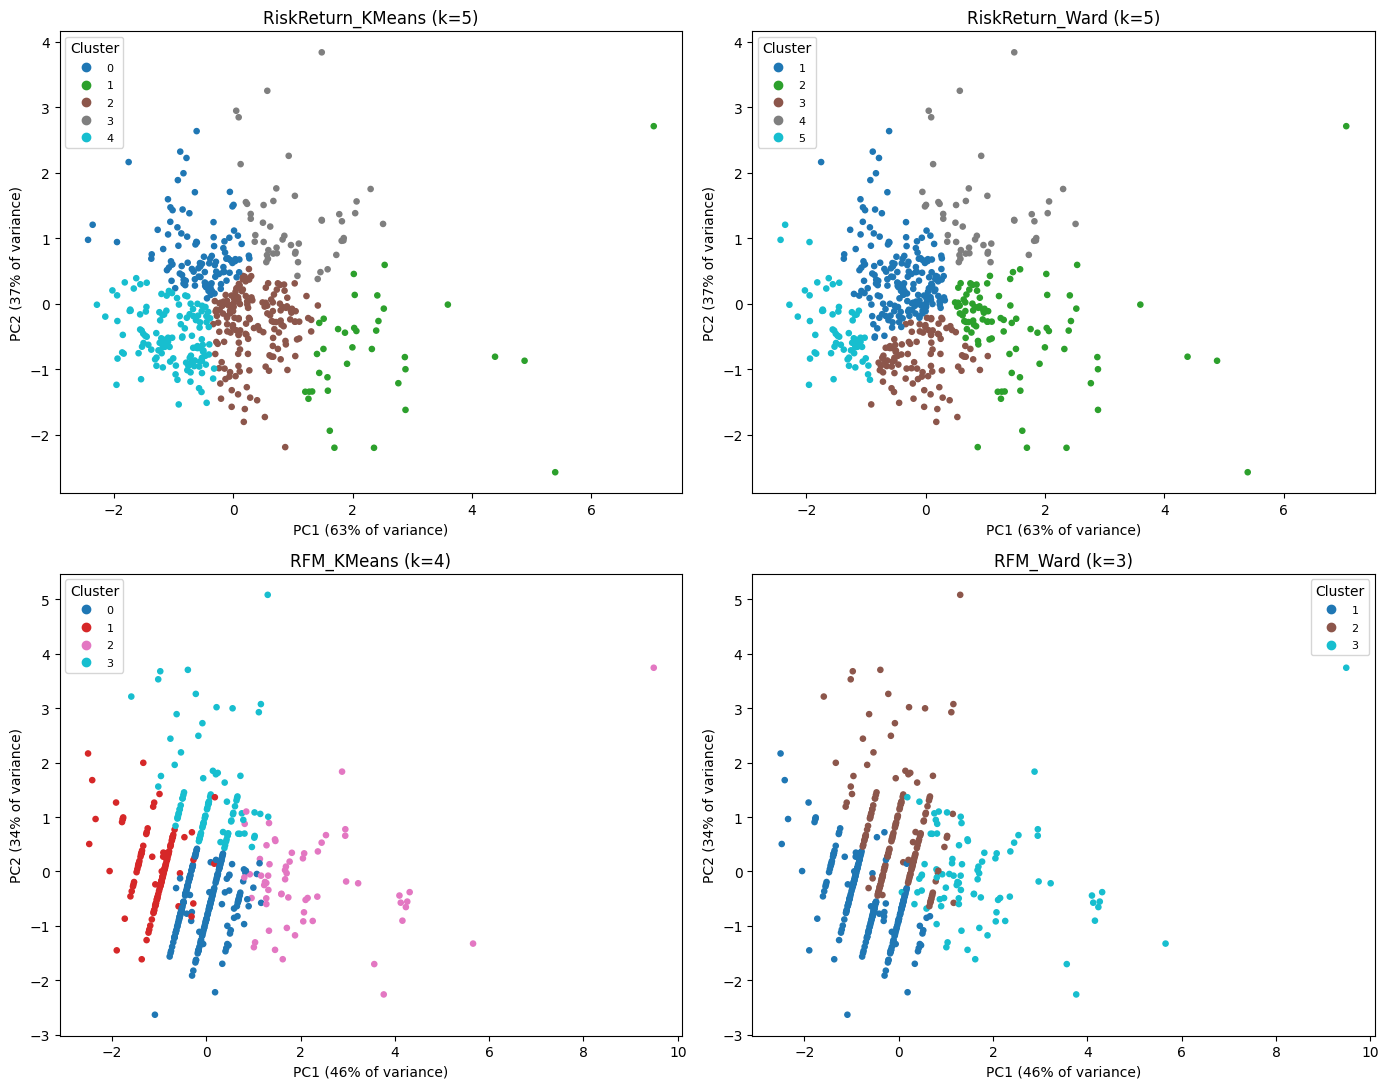

In [44]:
# Visualise the Clusters Using PCA

from sklearn.decomposition import PCA                                            # Import PCA for reducing the features to two dimensions.
fig, axes = plt.subplots(2, 2, figsize=(14, 11))                                 # four charts, one per clustering solution
for ax, col in zip(axes.ravel(), assign.columns):
    name = col.split("_")[0]                                                     # "RiskReturn" or "RFM"
    pca = PCA(n_components=2).fit(matrices[name])                                # find the two best axes
    P = pca.transform(matrices[name])                                            # each share's position on those axes
    sc = ax.scatter(P[:, 0], P[:, 1], c=assign[col], cmap="tab10", s=14)         # colour each dot by its cluster
    ax.set_title(f"{col} (k={K[tuple(col.split('_'))]})")
    ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.0%} of variance)")
    ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.0%} of variance)")
    ax.legend(*sc.legend_elements(), title="Cluster", fontsize=8)
plt.tight_layout(); plt.savefig("cluster_pca.png", dpi=150); plt.show()

In [45]:
# Compare the Results of Ward and K-Means Clustering

# Import the adjusted Rand index for comparing cluster results.
from sklearn.metrics import adjusted_rand_score

for name in ["RiskReturn", "RFM"]:
      # Get the cluster labels from both algorithms.
    a, b = assign[f"{name}_Ward"], assign[f"{name}_KMeans"]
    print(f"\n{name}: ARI Ward vs KMeans = {adjusted_rand_score(a, b):.3f}")     # Calculate how similar the two clustering results are.
    print(pd.crosstab(a, b, rownames=["Ward"], colnames=["KMeans"]))                 # Show how many shares appear in each pair of clusters.



RiskReturn: ARI Ward vs KMeans = 0.320
KMeans    0   1   2   3   4
Ward                       
1       100   0  51   0  32
2         0  37  51   4   0
3         0   0  64   0  34
4         3   0   0  45   0
5         3   0   0   0  63

RFM: ARI Ward vs KMeans = 0.287
KMeans    0    1   2   3
Ward                    
1       115  107   0   0
2        82   14   0  83
3        16    1  61   8


## 2.5 RFM sensitivity and correlated inputs

### 2.5.1 Correlation analysis

In [46]:
# Check Correlations Between the RFM Features
corr = final[["R", "F", "log1p_M"]].corr().round(3)                              # Calculate the correlation between R, F and log-transformed Monetary
print(corr)                                                                      # Display the correlation values.
corr.to_csv("rfm_correlations.csv")

             R      F  log1p_M
R        1.000 -0.346    0.152
F       -0.346  1.000    0.013
log1p_M  0.152  0.013    1.000


### 2.5.2 Removal of Monetary

In [47]:
# Compare Ward RFM Clustering With and Without Monetary
kw = K[("RFM", "Ward")]                                                          # Use the same number of clusters as the original Ward RFM solution

# Standardise R and F without including Monetary.
Xrf = pd.DataFrame(StandardScaler().fit_transform(final[["R", "F"]]), index=final.index, columns=["R", "F"])

# Apply Ward clustering using R and F only.
Z_rf = linkage(Xrf, method="ward")
lab_rf = cut_tree(Z_rf, n_clusters=kw).ravel() + 1

# Get the original Ward RFM cluster assignments.
lab_full = assign["RFM_Ward"]

print(f"k = {kw} | ARI (with M vs without M) = {adjusted_rand_score(lab_full, lab_rf):.3f}")   # Compare the two clustering results using ARI.
print("Silhouette, R and F only:", round(silhouette_score(Xrf, lab_rf), 3))                    # Check how well the R and F only clusters are separated.
print(pd.crosstab(lab_full, lab_rf, rownames=["With M"], colnames=["R,F only"]))               # Compare how shares are grouped in both solutions.

mbn = final["M"] / 1e9                                                           # traded value in $ billions
print("\nTraded value ($bn) by cluster, with Monetary:")
print(mbn.groupby(lab_full).describe()[["count", "mean", "50%", "min", "max"]].round(2))
print("\nTraded value ($bn) by cluster, without Monetary:")
print(mbn.groupby(lab_rf).describe()[["count", "mean", "50%", "min", "max"]].round(2))

k = 3 | ARI (with M vs without M) = 0.268
Silhouette, R and F only: 0.485
R,F only   1    2   3
With M               
1         66  151   5
2         59  119   1
3          0    2  84

Traded value ($bn) by cluster, with Monetary:
          count   mean    50%    min      max
RFM_Ward                                     
1         222.0  11.01  10.14   1.30    37.90
2         179.0  70.25  34.32  12.30  1847.70
3          86.0  48.25  21.45   4.37  1825.34

Traded value ($bn) by cluster, without Monetary:
   count   mean    50%   min      max
1  125.0  34.34  17.70  3.69   623.30
2  272.0  39.40  14.86  1.30  1847.70
3   90.0  46.22  20.49  4.37  1825.34


# Task 3 – Business intelligence and critical review

3.1 (data mart design) is written in the report only, so there is no code.

## 3.2.1 Sector composition of the clusters

Baseline sector mix (%):
 GICS Sector
Industrials               16.2
Financials                15.2
Information Technology    15.2
Health Care               11.9
Consumer Discretionary     9.7
Consumer Staples           6.6
Utilities                  6.2
Real Estate                6.2
Materials                  4.7
Energy                     4.1
Communication Services     4.1
Name: proportion, dtype: float64


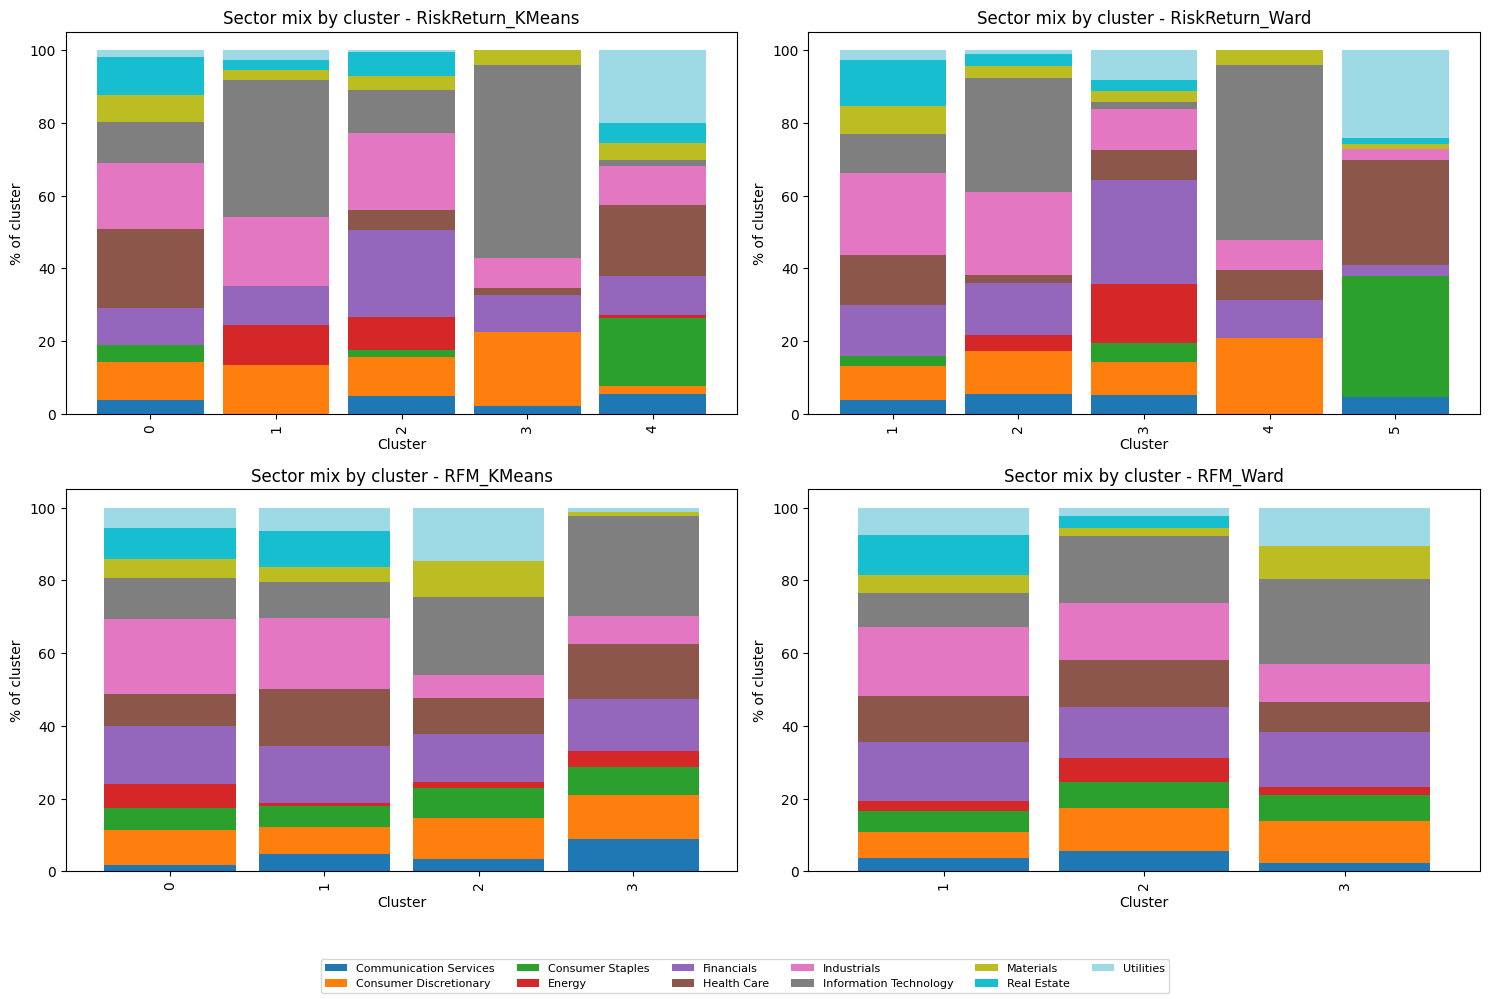


RiskReturn_KMeans: sector % in each cluster
Cluster                    0     1     2     3     4
GICS Sector                                         
Communication Services   3.8   0.0   4.8   2.0   5.4
Consumer Discretionary  10.4  13.5  10.8  20.4   2.3
Consumer Staples         4.7   0.0   1.8   0.0  18.6
Energy                   0.0  10.8   9.0   0.0   0.8
Financials              10.4  10.8  24.1  10.2  10.9
Health Care             21.7   0.0   5.4   2.0  19.4
Industrials             17.9  18.9  21.1   8.2  10.9
Information Technology  11.3  37.8  12.0  53.1   1.6
Materials                7.5   2.7   3.6   4.1   4.7
Real Estate             10.4   2.7   6.6   0.0   5.4
Utilities                1.9   2.7   0.6   0.0  20.2

RiskReturn_Ward: sector % in each cluster
Cluster                    1     2     3     4     5
GICS Sector                                         
Communication Services   3.8   5.4   5.1   0.0   4.5
Consumer Discretionary   9.3  12.0   9.2  20.8   0.0
Consumer St

In [48]:
# Compare the Sector Composition of Each Cluster

# Select the four clustering solutions to compare.
cols4 = ["RiskReturn_KMeans", "RiskReturn_Ward", "RFM_KMeans", "RFM_Ward"]
base = final["GICS Sector"].value_counts(normalize=True) * 100  # sector mix of ALL 487 shares, in %
print("Baseline sector mix (%):\n", base.round(1))

fig, axes = plt.subplots(2, 2, figsize=(15, 10))

for ax, col in zip(axes.ravel(), cols4):

    temp = final[["GICS Sector"]].copy()  # copy sector information
    temp["Cluster"] = assign[col].values  # add cluster assignments

    counts = temp.groupby(["Cluster", "GICS Sector"]).size().reset_index(name="Count")  # count shares in each sector and cluster
    totals = temp.groupby("Cluster").size().reset_index(name="Total")  # count total shares in each cluster
    counts = counts.merge(totals, on="Cluster")  # combine sector counts with cluster totals
    counts["Percentage"] = counts["Count"] / counts["Total"] * 100  # calculate percentage within each cluster

    ct = counts.pivot(index="Cluster", columns="GICS Sector", values="Percentage").fillna(0)  # arrange percentages for the chart
    ct.plot(kind="bar", stacked=True, ax=ax, legend=False, width=0.85, colormap="tab20")  # one stacked bar per cluster

    ax.set_title(f"Sector mix by cluster - {col}")
    ax.set_ylabel("% of cluster")
    ax.set_xlabel("Cluster")

h, l = axes[0, 0].get_legend_handles_labels()  # get sector names for one shared legend
fig.legend(h, l, loc="lower center", ncol=6, fontsize=8)
plt.tight_layout(rect=[0, 0.07, 1, 1])
plt.savefig("sector_composition.png", dpi=150)
plt.show()

for col in cols4:

    temp = final[["GICS Sector"]].copy()
    temp["Cluster"] = assign[col].values

    counts = temp.groupby(["Cluster", "GICS Sector"]).size().reset_index(name="Count")
    totals = temp.groupby("Cluster").size().reset_index(name="Total")
    counts = counts.merge(totals, on="Cluster")
    counts["Percentage"] = counts["Count"] / counts["Total"] * 100

    ct = counts.pivot(index="GICS Sector", columns="Cluster", values="Percentage").fillna(0)

    print(f"\n{col}: sector % in each cluster")
    print(ct.round(1).to_string())

# Compare Risk-return K-means (rows) with RFM K-means (columns)
comparison = assign.groupby(["RiskReturn_KMeans", "RFM_KMeans"]).size().unstack(fill_value=0)
print("\nRisk-return K-means (rows) vs RFM K-means (columns):")
print(comparison)
